# Stage 02a: Rejection Sampling to Guarantee Valid QLD Points
- Why Bounding-Box Sampling Falls Short
- shapely `Point` Fundamentals
- Directionality of Spatial Checks (`.within()` vs `.contains()`)
- Reproducibility (random seeds)
- Rejection Sampling

## Task
In Stage 2's main notebook, random points generated across a rectangular QLD bounding box didn't all fall inside the real QLD boundary (7 of 10 landed inside). This notebook explores an alternative: generating points one at a time and only keeping the ones that are genuinely valid, repeating until exactly 10 are collected. Steps to work through:
- Generate a single candidate point using `shapely.Point(long, lat)`, understanding `Point` as a single, immutable location built from `(x, y)` i.e. `(longitude, latitude)`
- Test the candidate against the real QLD boundary using `point.within(qld.union_all())`
- Keep the point only if it's valid, and repeat in a `while` loop until 10 valid points are collected
- Combine the valid coordinates with freshly generated `construction_type` and `sum_insured` values to build a complete exposure dataset
- Save the result separately as `exposure_data_resampled.csv`, and re-validate that all 10 points fall inside QLD

*This notebook is a side quest exploring rejection sampling as a technique — not used in the main pipeline. See `01_exposure_exploration.ipynb` for the main Stage 1/2 workflow.*

In [11]:
import pandas as pd 
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
import folium

np.random.seed(42)

In [ ]:
# Download boundaries from website and check for name of states
world_states = gpd.read_file("https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip")
world_states.columns

Index(['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2',
       'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt',
       ...
       'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT', 'FCLASS_NL',
       'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'FCLASS_TLC', 'geometry'],
      dtype='str', length=122)

In [ ]:
# Check Queensland is an option to filter for
qld = world_states[(world_states["name"] == "Queensland") & (world_states["iso_a2"] == "AU")]
qld

,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


In [ ]:
# Generate and filter points
valid_points = []

while len(valid_points) < 10:
    # randomly generate latitude and longitude points
    lat = np.random.uniform(-28, -16)
    long = np.random.uniform(145, 153)

    # use the coordinates to represent one location that can be used to ask questions like below.
    point = Point(long, lat)

    # is the point inside the state of Queensland?
    inside = point.within(qld.union_all())

    # if yes, then keep point. coords pulls the lat and long out
    # flatten gives [long, lat] instead of [[long, lat]]
    if inside:
        point_xy = np.array(point.coords).flatten()
        valid_points.append(point_xy)

    # otherwise, go back to generating points
    pass

print(len(valid_points))
valid_points


10


[array([146.24795616, -26.12777631]),
 array([151.92940917, -27.30299665]),
 array([152.75927882, -27.75298607]),
 array([146.46723608, -25.81810039]),
 array([149.19805145, -24.34909308]),
 array([147.32983312, -22.81665978]),
 array([146.11595089, -20.65776526]),
 array([147.93089475, -24.49426422]),
 array([149.11387551, -25.60391461]),
 array([145.3716033 , -20.89102517])]

In [9]:
# Defining Data
policy_id = np.array([1,2,3,4,5,6,7,8,9,10])

sum_insured = np.random.uniform(2e5, 8e5, size=10)

materials = ["timber", "brick_veneer", "concrete_block"]
construction_type = np.random.choice(materials, size=10)

valid_points_array = np.array(valid_points)

long = valid_points_array[:,0]
lat = valid_points_array[:,1]

In [ ]:
# Building the DataFrame
df = pd.DataFrame({
    "policy_id": policy_id,
    "latitude": lat,
    "longitude": long,
    "construction_type": construction_type,
    "sum_insured": sum_insured
})

# Don't need the print statement to see the table in a notebook
df

,policy_id,latitude,longitude,construction_type,sum_insured
0,1,-26.127776,146.247956,timber,257246.069894
1,2,-27.302997,151.929409,brick_veneer,422490.951319
2,3,-27.752986,152.759279,concrete_block,601304.751598
3,4,-25.818100,146.467236,concrete_block,599553.413970
4,5,-24.349093,149.198051,brick_veneer,554778.672625
5,6,-22.816660,147.329833,concrete_block,364833.075794
6,7,-20.657765,146.115951,concrete_block,536746.055509
7,8,-24.494264,147.930895,timber,429756.124852
8,9,-25.603915,149.113876,concrete_block,783027.257233
9,10,-20.891025,145.371603,concrete_block,709348.294560


In [15]:
# Round insured amounts
df["sum_insured"] = df["sum_insured"].round(2)
df

,policy_id,latitude,longitude,construction_type,sum_insured
0,1,-26.127776,146.247956,timber,257246.07
1,2,-27.302997,151.929409,brick_veneer,422490.95
2,3,-27.752986,152.759279,concrete_block,601304.75
3,4,-25.818100,146.467236,concrete_block,599553.41
4,5,-24.349093,149.198051,brick_veneer,554778.67
5,6,-22.816660,147.329833,concrete_block,364833.08
6,7,-20.657765,146.115951,concrete_block,536746.06
7,8,-24.494264,147.930895,timber,429756.12
8,9,-25.603915,149.113876,concrete_block,783027.26
9,10,-20.891025,145.371603,concrete_block,709348.29


In [ ]:
# Save dataset
df.to_csv("exposure_data_QLD_only.csv", index=False)

In [ ]:
# Double check that all the points are inside QLD
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"])
)

gdf["in_qld"] = gdf.within(qld.union_all())
print(gdf["in_qld"].value_counts())

gdf

in_qld
True    10
Name: count, dtype: int64


,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-26.127776,146.247956,timber,257246.07,POINT (146.24796 -26.12778),True
1,2,-27.302997,151.929409,brick_veneer,422490.95,POINT (151.92941 -27.303),True
2,3,-27.752986,152.759279,concrete_block,601304.75,POINT (152.75928 -27.75299),True
3,4,-25.818100,146.467236,concrete_block,599553.41,POINT (146.46724 -25.8181),True
4,5,-24.349093,149.198051,brick_veneer,554778.67,POINT (149.19805 -24.34909),True
5,6,-22.816660,147.329833,concrete_block,364833.08,POINT (147.32983 -22.81666),True
6,7,-20.657765,146.115951,concrete_block,536746.06,POINT (146.11595 -20.65777),True
7,8,-24.494264,147.930895,timber,429756.12,POINT (147.93089 -24.49426),True
8,9,-25.603915,149.113876,concrete_block,783027.26,POINT (149.11388 -25.60391),True
9,10,-20.891025,145.371603,concrete_block,709348.29,POINT (145.3716 -20.89103),True


<Axes: >

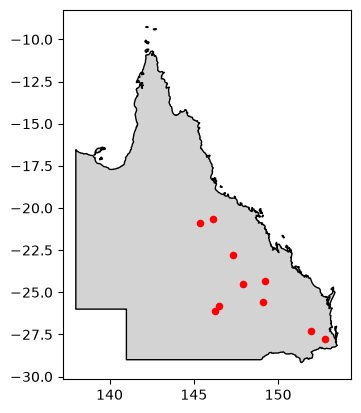

In [ ]:
# Visual check
ax = qld.plot(color="lightgrey", edgecolor="black")
gdf.plot(ax=ax, color="red", markersize=20)